# Weather Trends

*Udacity Data Analyst Nanodegree · Lucas Vieira · June 2024, updated September 2026*

In this project, I analyze local and global temperature data and compare the temperature trends where I live with global trends. I also include two more cities in the analysis: Amsterdam and Dublin.

This notebook is the reproducible version of the report. Every number and chart below comes from the files in `data/`, so anyone can run it again and get the same results.

**What changed in the September 2026 update**

- The steps done by hand in Excel (continent lookup, moving averages) are now code.
- The data goes up to 2020 for the cities and 2024 for the global average, straight from Berkeley Earth, the source behind the Udacity database.
- Two data quality issues are explained: cities with identical series and incomplete years.
- The main comparison is now the **change** in temperature over time, not only the level.

In [1]:
import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = sqlite3.connect(ROOT / "data" / "processed" / "weather.db")

def load_queries(name):
    """Read the named queries of a file in sql/ (blocks that start with '-- name: ...')."""
    text = (ROOT / "sql" / name).read_text()
    return dict(re.findall(r"-- name: (\w+)\n(.*?;)", text, re.S))

def sql(query):
    return pd.read_sql(query, DB)

COLORS = {"Global": "#52514e", "Campinas": "#2a78d6", "Amsterdam": "#eb6834", "Dublin": "#1baf7a"}
plt.rcParams.update({
    "figure.figsize": (10, 4.8), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Data sources

The Udacity workspace had a PostgreSQL database with three tables:

- `city_list`: a list of cities and countries in the database.
- `city_data`: the average temperature of each city by year (°C).
- `global_data`: the average global temperature by year (°C).

The workspace is not public, so this project rebuilds the same schema in SQLite (`data/processed/weather.db`) with `scripts/build_dataset.py`:

| Table | Where it comes from |
|---|---|
| `city_list` | the 342 rows I exported from the Udacity database (`data/raw/udacity/city_list.csv`) |
| `city_data` | Berkeley Earth, one file per city, monthly values up to December 2020 |
| `global_data` | Berkeley Earth global land average, monthly values up to December 2024 |

The original CSV exports from Udacity (global, Campinas, Amsterdam and Dublin) are kept in `data/raw/udacity/` and used in section 4 to check that both sources tell the same story.

## 2. Understanding the city list

After seeing the schema, I decided to understand the data available by gathering general information, like the different cities and countries.

In [2]:
explore = load_queries("01_explore.sql")
sql(explore["list_size"])

,rows,city_names,countries
0,342,329,135


There are 342 rows but only 329 different city names. A first interesting insight is about duplicate city names: Barcelona is a city in Spain and in Venezuela, and Colombo is in Sri Lanka and in Brazil. If we only queried by city name, the data could have been compromised with wrongly mixed values, so every query below filters by city **and** country.

In [3]:
sql(explore["duplicate_city_names"])

,city,country
0,Alexandria,Egypt
1,Alexandria,United States
2,Barcelona,Spain
3,Barcelona,Venezuela
4,Birmingham,United Kingdom
5,Birmingham,United States
6,Colombo,Brazil
7,Colombo,Sri Lanka
8,Hyderabad,India
9,Hyderabad,Pakistan


### Cities by continent

The database has no continent column. In the 2024 version I added it in Excel: a list of countries by continent ([statisticstimes.com](https://statisticstimes.com/geography/countries-by-continents.php)), a VLOOKUP, and some manual fixes, because the two lists spell 18 countries differently ("United States" and "United States of America", "Russia" and "Russian Federation"...).

Now the same step is a merge in `build_dataset.py`, with the 18 fixes written down in `COUNTRY_ALIASES`. The script stops with an error if any country is left without a continent, so nothing is lost silently. As in the original report, North and South America are counted together as Americas.

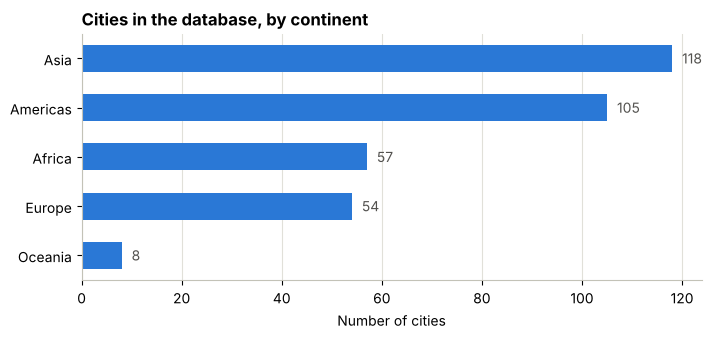

In [4]:
continents = pd.read_csv(ROOT / "data" / "processed" / "cities_by_continent.csv")
by_continent = continents["continent_group"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(by_continent.index, by_continent.values, color="#2a78d6", height=0.55)
for y, value in enumerate(by_continent.values):
    ax.text(value + 2, y, str(value), va="center", color="#52514e")
ax.set_title("Cities in the database, by continent")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of cities")
plt.show()

Asia is the most represented continent, with 118 cities. North and South America follow with 105 cities combined. The least represented is Oceania, with only 8 cities. The counts are the same as in the 2024 version, which confirms the Excel version was right.

## 3. Brazil

There are 11 Brazilian cities in the database.

In [5]:
brazil = load_queries("02_brazil.sql")
sql(brazil["brazil_summary"])

,city,min_temp,max_temp,avg_temp,min_year,max_year,non_null_years
0,Belo Horizonte,19.35,22.69,20.83,1832,2020,182
1,Campinas,18.50,21.71,19.98,1832,2020,182
2,Colombo,16.52,19.58,17.90,1832,2020,182
3,Curitiba,16.52,19.58,17.90,1832,2020,182
4,Fortaleza,25.85,28.49,26.94,1851,2020,134
5,Guarulhos,18.50,21.71,19.98,1832,2020,182
6,Manaus,25.82,28.44,26.73,1824,2020,178
7,Porto Alegre,17.47,20.32,18.75,1832,2020,182
8,Recife,24.16,26.92,25.35,1832,2020,178
9,Rio de Janeiro,21.99,25.39,23.54,1832,2020,182


To understand how these cities are spread across the country, I put them on a map. The coordinates came from Excel's Geography data type (`data/reference/brazil_cities.csv`).

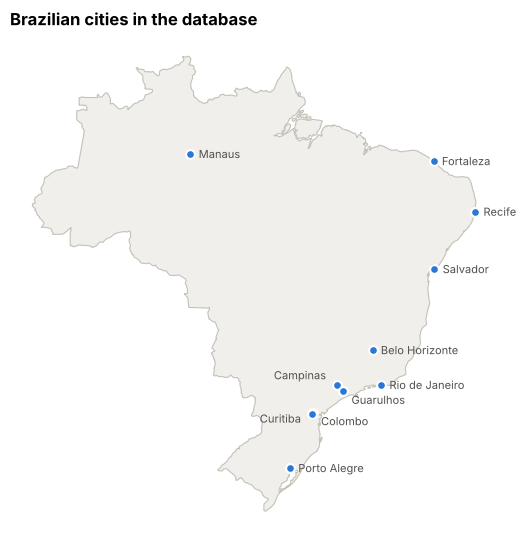

In [6]:
import json

cities_br = pd.read_csv(ROOT / "data" / "reference" / "brazil_cities.csv")
outline = json.loads((ROOT / "data" / "reference" / "brazil_outline.geojson").read_text())["geometry"]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for polygon in outline["coordinates"]:
    lon, lat = zip(*polygon[0])
    ax.fill(lon, lat, color="#f0efec", edgecolor="#c3c2b7", linewidth=0.8)
ax.scatter(cities_br["longitude"], cities_br["latitude"], s=40, color="#2a78d6", edgecolor="white", linewidth=1.5, zorder=3)
# Label offsets in points, so close cities do not overlap.
offsets = {"Campinas": (-8, 4, "right"), "Guarulhos": (6, -9, "left"), "Colombo": (6, -9, "left"), "Curitiba": (-8, -6, "right")}
for _, row in cities_br.iterrows():
    dx, dy, ha = offsets.get(row["city"], (6, -3, "left"))
    ax.annotate(row["city"], (row["longitude"], row["latitude"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color="#52514e", ha=ha)
ax.set_aspect(1 / np.cos(np.radians(14)))
ax.set_axis_off()
ax.set_title("Brazilian cities in the database")
plt.show()

There is a concentration of 7 cities in the southeast and south of the country, 3 in the northeast and 1 in the north. The Midwest is not represented. The 11 cities are in 9 states, with lower temperatures in the south and higher temperatures in the north and northeast.

### Two pairs of cities have exactly the same data

In the 2024 version I wrote that Colombo and Curitiba share the lowest temperatures because they are very close to each other. The real reason is in how the data is made. Berkeley Earth does not measure each city: it estimates the temperature on a grid that covers the whole planet, and a city gets the values of the grid cell it falls in. Colombo and Curitiba fall in the same cell, and so do Campinas and Guarulhos. Their series are not similar, they are identical, year by year:

In [7]:
sql(brazil["identical_series"])

,city_a,city_b,common_years,equal_years
0,Campinas,Guarulhos,182,182
1,Colombo,Curitiba,182,182


The header of each Berkeley Earth file confirms it. The cell used for Campinas lists *São Paulo, Guarulhos, Campinas, São Bernardo do Campo, Osasco* as its nearby cities, and the one used for Curitiba lists *Curitiba, Ponta Grossa, São José dos Pinhais, Colombo*.

What this means for the analysis: the database has 11 Brazilian city names but only 9 independent series, and "Campinas" really means "the region around São Paulo". That is still the nearest data to where I live, so Campinas stays as my local city.

## 4. Checking the data before comparing it

Before plotting anything, I compared the original Udacity exports with the current Berkeley Earth files, and looked at how missing values were handled.

In [8]:
udacity = {name: pd.read_csv(ROOT / "data" / "raw" / "udacity" / f"{file}.csv").set_index("year")["avg_temp"]
           for name, file in [("Global", "global_data"), ("Campinas", "campinas"), ("Amsterdam", "amsterdam"), ("Dublin", "dublin")]}
annual = pd.read_csv(ROOT / "data" / "processed" / "annual_temperatures.csv")
current = {name: group.set_index("year")["avg_temp"] for name, group in annual.groupby("series")}

rows = []
for name, old in udacity.items():
    both = pd.concat([old, current[name]], axis=1, keys=["udacity", "berkeley"]).loc[1854:2012].dropna()
    diff = both["berkeley"] - both["udacity"]
    rows.append({"series": name, "years compared": len(both), "mean difference (°C)": round(diff.mean(), 2),
                 "correlation": round(both.corr().iloc[0, 1], 3)})
pd.DataFrame(rows)

,series,years compared,mean difference (°C),correlation
0,Global,159,-0.03,0.994
1,Campinas,159,0.23,0.947
2,Amsterdam,159,-0.02,0.999
3,Dublin,159,0.05,0.989


Between 1854 and 2012 the two versions move together (high correlation). The level can differ by up to a few tenths of a degree, because Berkeley Earth recalculates its baseline in every release. That is one more reason to compare changes over time and not only the absolute temperatures.

Two more points came up in this check:

- **Missing years became zeros.** In the 2024 spreadsheet, the years without data for Campinas (before 1832 and 1844–1850) were stored as 0. A 0 °C average is impossible for Campinas, so I started the chart in 1854 to leave those years out. Here they are left empty (NaN) instead, so no calculation can use them by mistake.
- **2013 is an incomplete year in the Udacity data.** The source stops partway through 2013, so the 2013 average misses the last months of the year. For Campinas, those are warm months, and the 2013 value came out about 0.5 °C too low. Now a year only counts if it has all 12 months.

In [9]:
print("Udacity Campinas, 2013:", udacity["Campinas"].loc[2013], "°C (part of the year)")
print("Berkeley Earth Campinas, 2013:", current["Campinas"].loc[2013], "°C (full year)")

Udacity Campinas, 2013: 20.07 °C (part of the year)
Berkeley Earth Campinas, 2013: 20.59 °C (full year)


## 5. Local and global trends

### Moving average

For the moving average, I chose a 4-year period because it provides a more stable representation of the data, minimizes the influence of single-year anomalies, and is still responsive enough to capture meaningful changes, unlike very long moving averages that can over-smooth the data. The calculation starts in 1854 to avoid the missing years of Campinas.

In the 2024 version the moving average was an Excel formula. Here it is a SQL window function (`sql/03_local_vs_global.sql`) and a pandas `rolling` in the chart below.

In [10]:
local = load_queries("03_local_vs_global.sql")
sql(local["moving_average"]).head(8)

,year,city,avg_temp,ma_4_years
0,1854,Campinas,19.58,NaN
1,1855,Campinas,19.65,NaN
2,1856,Campinas,19.34,NaN
3,1857,Campinas,19.90,19.62
4,1858,Campinas,18.94,19.46
5,1859,Campinas,19.58,19.44
6,1860,Campinas,20.21,19.66
7,1861,Campinas,19.50,19.56


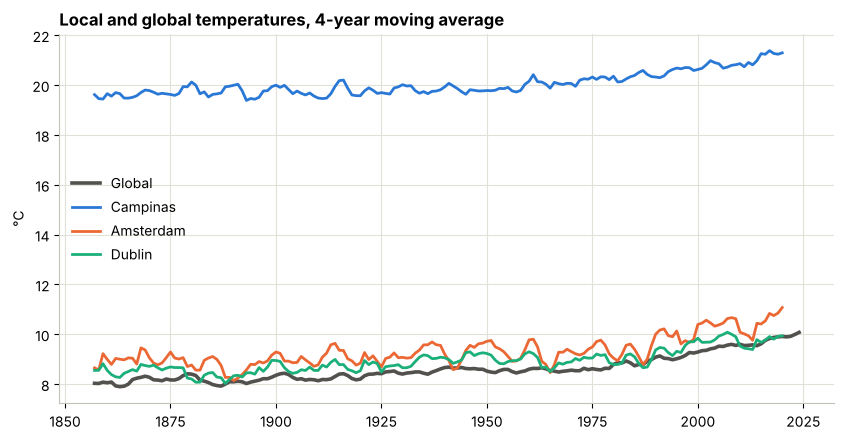

In [11]:
SERIES = ["Global", "Campinas", "Amsterdam", "Dublin"]

fig, ax = plt.subplots()
for name in SERIES:
    s = current[name].loc[1854:].rolling(4).mean()
    ax.plot(s.index, s.values, color=COLORS[name], linewidth=2.6 if name == "Global" else 2, label=name)
ax.set_title("Local and global temperatures, 4-year moving average")
ax.set_ylabel("°C")
ax.legend(loc="center left", frameon=False)
plt.show()

This is the chart from the 2024 version, with the new data. It shows that Campinas is about 11 °C hotter than the global average, and Amsterdam and Dublin are slightly hotter than it. But it hides the most important part: the lines are far apart, so it is hard to see that all of them are going up at a similar pace.

### Change compared with 1854–1900

To compare the trends directly, I subtract from each series its own average of 1854–1900. The result is how much warmer (or colder) each year was than the second half of the 19th century. This is the same idea climate scientists use when they talk about warming "since pre-industrial times".

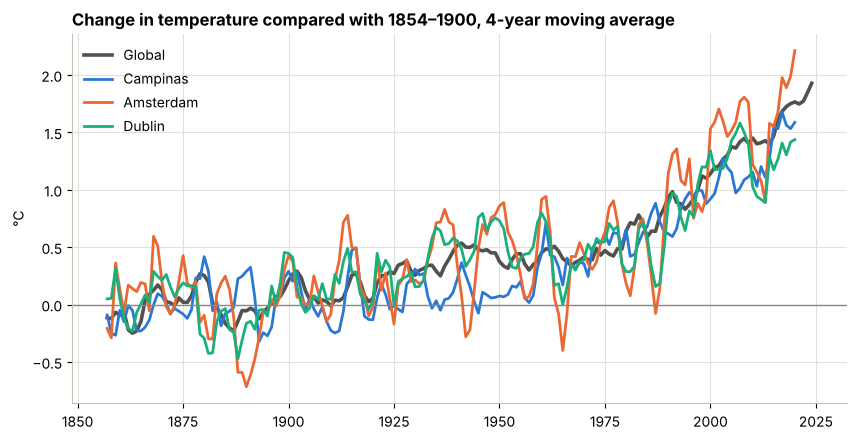

In [12]:
fig, ax = plt.subplots()
for name in SERIES:
    s = current[name].loc[1854:]
    change = (s - s.loc[1854:1900].mean()).rolling(4).mean()
    ax.plot(change.index, change.values, color=COLORS[name], linewidth=2.6 if name == "Global" else 2, label=name)
ax.axhline(0, color="#898781", linewidth=1)
ax.set_title("Change in temperature compared with 1854–1900, 4-year moving average")
ax.set_ylabel("°C")
ax.legend(loc="upper left", frameon=False)
plt.show()

In [13]:
sql(local["change_vs_1854_1900"])

,series,avg_1854_1900,avg_1991_2020,change
0,Amsterdam,8.86,10.33,1.47
1,Global,8.15,9.49,1.34
2,Campinas,19.71,20.89,1.18
3,Dublin,8.50,9.68,1.18


Now the story is clear. The four series rose slowly during most of the 20th century, and then much faster from around 1980. Between 1991 and 2020, Amsterdam was 1.47 °C warmer than in 1854–1900, the global land average 1.34 °C, and Campinas and Dublin 1.18 °C.

### The most recent years

The global series goes up to 2024, four years beyond the city files.

In [14]:
g = current["Global"]
baseline = g.loc[1854:1900].mean()
recent = (g.loc[2015:] - baseline).round(2).rename("change vs 1854–1900 (°C)")
print("Five hottest years on record:", g.sort_values(ascending=False).head(5).index.tolist())
recent.to_frame()

Five hottest years on record: [2024, 2023, 2020, 2016, 2019]


,change vs 1854–1900 (°C)
year,
2015,1.68
2016,1.88
2017,1.75
2018,1.59
2019,1.78
2020,1.94
2021,1.68
2022,1.68
2023,2.08


2024 was the hottest year in the record, 2.27 °C above 1854–1900 on land, and the five hottest years all happened after 2015.

### Linear trend

A linear regression on each series gives the average speed of the change.

In [15]:
def trend(series, start, per=10):
    s = series.loc[start:].dropna()
    return np.polyfit(s.index, s.values, 1)[0] * per

pd.DataFrame({
    "°C per century since 1854": {n: round(trend(current[n], 1854, 100), 2) for n in SERIES},
    "°C per decade since 1970": {n: round(trend(current[n], 1970), 2) for n in SERIES},
})

,°C per century since 1854,°C per decade since 1970
Global,0.97,0.29
Campinas,0.83,0.23
Amsterdam,0.96,0.35
Dublin,0.80,0.22


Since 1970, the global land average warmed about 0.3 °C per decade, three times faster than the long-term pace of about 1 °C per century.

## 6. Key observations

Where each number comes from:

- **Change between periods**: the `change_vs_1854_1900` query in section 5, which compares the average of 1991–2020 with the average of 1854–1900. It is the same as a 30-year moving average at 2020, because the 30 years that end in 2020 are exactly 1991–2020. Shorter windows end higher, since they only average the most recent and hottest years (Campinas with a 20-year window: +1.32 °C in 2020).
- **Hottest years**: the yearly values, with no moving average.
- **Pace since 1970**: the linear trend table at the end of section 5.

The observations:

- **Campinas** was 1.18 °C warmer in 1991–2020 than in 1854–1900, a bit less than the global land average (+1.34 °C), even though it is about 11 °C hotter in absolute terms. Its 10-year average passed +0.5 °C in 1978 and +1.0 °C in 2002. The hottest years were all recent: 2015 (21.71 °C), 2019 (21.59 °C) and 2014 (21.58 °C).
- **Amsterdam** warmed the most of the four, 1.47 °C, and is the only city above the global land average. Its trend since 1970 is also the steepest, 0.35 °C per decade. The hottest years: 2014 (11.48 °C), 2020 (11.44 °C) and 2018 (11.13 °C).
- **Dublin** warmed 1.18 °C, the same as Campinas, but the two got there differently. Dublin's hottest years came earlier, 2007 (10.27 °C), 2014 (10.23 °C) and 2006 (10.12 °C), and since 1970 it warmed 0.22 °C per decade, the slowest pace of the four (Campinas: 0.23).
- **Global (land)** warmed 1.34 °C between the two periods. Its series goes four years further than the cities: 2024 was the hottest year in the record, 2.27 °C above 1854–1900, and the five hottest years were 2024, 2023, 2020, 2016 and 2019. Since 1970 it warmed 0.29 °C per decade, three times its long-term pace (0.97 °C per century since 1854).

### Why did Amsterdam warm more than Campinas?

A reader in Brazil may find this surprising: Brazil is much hotter than the Netherlands, so the numbers may look wrong at first. But being hotter and warming faster are different things. This analysis compares the change in temperature, not its level.

The result is consistent with a global climate pattern known as **polar amplification**: regions at higher latitudes, closer to the poles, tend to warm more and faster than tropical and subtropical regions, such as Southeast Brazil. The effect is strongest in the Arctic and fades towards the equator ([Serreze & Barry, 2011](https://doi.org/10.1016/j.gloplacha.2011.03.004)). Amsterdam is at 52°N; Campinas is at 23°S.

Latitude is not the only factor, though. Dublin, even further north (53°N) but on the Atlantic coast, warmed as much as Campinas, likely because the ocean around it warms more slowly than land.

Over the whole period, the four series rose slowly during most of the 20th century and much faster from around 1980. With a 10-year moving average, all of them passed +1.0 °C between 1995 and 2002.

The data also reveals potential health risks from more frequent and severe heatwaves, especially for vulnerable groups such as the elderly and children. The world is getting hotter, both locally and globally, and the effects need ongoing efforts to be mitigated.

## 7. Limitations and next steps

- The city series end in 2020, because the city files Berkeley Earth makes available are from a January 2021 release. A source like ERA5 (Copernicus) could extend them to today.
- The city values come from a grid with points about 1.6° apart (around 170 km), so they describe a region, not a city. Campinas and São Paulo are the same series here.
- Yearly averages hide seasons and extremes. Monthly data would allow analysing heatwaves directly.
- Linking climate change to the carbon credit market and ESG initiatives is still an open idea from the 2024 version.
- This is an educational project. Running the analysis again with other choices could change the numbers shown here: a different scope (other cities, a whole country instead of one grid point), another baseline period or moving average window, another data source or release, or another way of handling missing data. The choices made here are explained along the notebook so they can be questioned and changed.

## References

- Berkeley Earth. *Land temperature data*. https://berkeleyearth.org/data/
- Udacity. Data Analyst Nanodegree, project "Explore Weather Trends".
- Statistics Times. *Countries by continents*. https://statisticstimes.com/geography/countries-by-continents.php
- Natural Earth. *Admin 0 – Countries* (1:50m). https://www.naturalearthdata.com
- Serreze, M. C., & Barry, R. G. (2011). Processes and impacts of Arctic amplification: A research synthesis. *Global and Planetary Change*, 77(1–2), 85–96. https://www.sciencedirect.com/science/article/abs/pii/S0921818111000397
- Statistics How To. *Moving average*. https://www.statisticshowto.com/probability-and-statistics/statistics-definitions/moving-average/